
# Part 1: Install Libraries and Login

In [1]:
!pip install -q -U transformers datasets accelerate bitsandbytes

import os
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import warnings
from typing import List

warnings.filterwarnings('ignore')

from huggingface_hub import login, hf_hub_download
from datasets import Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
)

print("=" * 60)
print("SYSTEM INFORMATION")
print("=" * 60)
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("WARNING: No GPU detected! This notebook requires a GPU.")
print("=" * 60)

# Authenticate with Hugging Face
HF_TOKEN = os.environ.get("HF_TOKEN")  # set your Hugging Face token as an environment variable
login(token=HF_TOKEN)
print('done :)')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 82.2 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 494.8/494.8 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 MB 26.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 79.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 83.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 61.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 43.2 

2025-09-01 20:26:10.379625: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756758370.589479      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756758370.646613      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu124
CUDA available: True
GPU Device: Tesla T4
GPU Memory: 14.74 GB
done :)


In [2]:
!nvidia-smi

Mon Sep  1 20:26:38 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.03              Driver Version: 560.35.03      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!pip install --upgrade transformers peft accelerate datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 5.0 MB/s eta 0:00:00:00:010:01
  Attempting uninstall: peft
    Found existing installation: peft 0.15.2
    Uninstalling peft-0.15.2:
      Successfully uninstalled peft-0.15.2


In [4]:
# Model configuration
MODEL_ID = "google/gemma-2-2b-it"

# Part 2: Data Preparation

In [5]:
def download_and_filter_dataset():
    """Downloads and filters the SlimOrca dataset."""
    repo_id = "miladmim/slim-orca-dedup-chat-50k-persian"
    filename = "data.jsonl"
    print(f"Downloading dataset from: {repo_id}")
    file_path = hf_hub_download(repo_id=repo_id, filename=filename, repo_type="dataset")

    all_data = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            all_data.append(json.loads(line.strip()))

    target_pattern = 'system -> user -> assistant'
    filtered_data = []
    for conversation in tqdm(all_data, desc="Filtering conversations"):
        roles = [msg.get('role', 'unknown') for msg in conversation]
        pattern = " -> ".join(roles)
        if pattern == target_pattern:
            filtered_data.append(conversation)

    print(f"Filtered dataset: {len(filtered_data)} valid conversations")
    return filtered_data

def create_formatted_dataset(conversations: List, tokenizer, max_samples: int):
    """Formats the dataset using Gemma's chat template."""
    print(f"Formatting {min(len(conversations), max_samples)} samples...")
    formatted_data = []
    for conversation in tqdm(conversations[:max_samples], desc="Formatting"):
        messages = [
            {"role": "user", "content": f"{conversation[0]['content']}\n{conversation[1]['content']}"},
            {"role": "model", "content": conversation[2]['content']}
        ]
        text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        formatted_data.append({"text": text})

    return formatted_data

def prepare_datasets(formatted_data: List, tokenizer, max_length: int = 512):
    """Tokenizes and splits the dataset."""
    dataset = Dataset.from_list(formatted_data)
    def tokenize_function(examples):
        tokenized = tokenizer(
            examples["text"], padding="max_length", truncation=True, max_length=max_length
        )
        tokenized["labels"] = tokenized["input_ids"].copy()
        return tokenized

    tokenized_dataset = dataset.map(
        tokenize_function, batched=True, remove_columns=["text"], desc="Tokenizing"
    )
    # Simple train/validation split for the small subset
    temp_split = tokenized_dataset.train_test_split(test_size=0.2, seed=42)
    train_dataset = temp_split["train"]
    val_dataset = temp_split["test"]
    print(f"Dataset splits created: Training ({len(train_dataset)}), Validation ({len(val_dataset)})")
    return train_dataset, val_dataset

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Download, filter, and prepare a subset of the data
print("Preparing a subset of the dataset (100 samples)...")
all_conversations = download_and_filter_dataset()
# Using a subset of 100 as requested
subset_data = create_formatted_dataset(all_conversations, tokenizer, max_samples=100)
train_dataset, val_dataset = prepare_datasets(subset_data, tokenizer)

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Preparing a subset of the dataset (100 samples)...


data.jsonl:   0%|          | 0.00/97.8M [00:00<?, ?B/s]

Filtering conversations:   0%|          | 0/40458 [00:00<?, ?it/s]

Filtered dataset: 39933 valid conversations
Formatting 100 samples...


Formatting:   0%|          | 0/100 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/100 [00:00<?, ? examples/s]

Dataset splits created: Training (80), Validation (20)


# PART 4: TRADITIONAL FINE-TUNING OF SPECIFIC LAYERS

In [6]:
# 1. Load Model with bfloat16
# ===============================
print(f"Loading model: {MODEL_ID} with bfloat16 precision...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    trust_remote_code=True,
    attn_implementation='eager'
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✓ Model loaded successfully in bfloat16.")
print(f"GPU memory used after loading: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")

Loading model: google/gemma-2-2b-it with bfloat16 precision...


config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/241M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

✓ Model loaded successfully in bfloat16.
GPU memory used after loading: 2.40 GB


In [7]:
# 2. Extract and Analyze Model Structure
# =======================================
print("\n--- Model Structure (Layers) ---")
# The main transformer blocks are in model.model.layers
total_layers = len(model.model.layers)
print(f"Total number of transformer layers found: {total_layers}")


--- Model Structure (Layers) ---
Total number of transformer layers found: 26


In [8]:
# 3. Freeze All Layers, Then Unfreeze Specific Layers
# ====================================================
print("\nFreezing all model layers initially...")
for param in model.parameters():
    param.requires_grad = False

print("Unfreezing the first 2, last 2, and the lm_head layers...")

# Unfreeze the first two layers
for i in range(2):
    for param in model.model.layers[i].parameters():
        param.requires_grad = True

# Unfreeze the last two layers
for i in range(total_layers - 2, total_layers):
    for param in model.model.layers[i].parameters():
        param.requires_grad = True

# Unfreeze the lm_head (crucial for prediction)
for param in model.lm_head.parameters():
    param.requires_grad = True

# Verify which parameters are trainable
print("\n--- Trainable Parameters ---")
trainable_params = 0
all_param = 0
for name, param in model.named_parameters():
    all_param += param.numel()
    if param.requires_grad:
        print(f"  - Layer/Parameter: {name}")
        trainable_params += param.numel()

print("----------------------------")
print(
    f"Trainable params: {trainable_params/1e6:.2f}M || All params: {all_param/1e9:.2f}B || "
    f"Trainable %: {100 * trainable_params / all_param:.4f}"
)



Freezing all model layers initially...
Unfreezing the first 2, last 2, and the lm_head layers...

--- Trainable Parameters ---
  - Layer/Parameter: model.embed_tokens.weight
  - Layer/Parameter: model.layers.0.self_attn.q_proj.weight
  - Layer/Parameter: model.layers.0.self_attn.k_proj.weight
  - Layer/Parameter: model.layers.0.self_attn.v_proj.weight
  - Layer/Parameter: model.layers.0.self_attn.o_proj.weight
  - Layer/Parameter: model.layers.0.mlp.gate_proj.weight
  - Layer/Parameter: model.layers.0.mlp.up_proj.weight
  - Layer/Parameter: model.layers.0.mlp.down_proj.weight
  - Layer/Parameter: model.layers.0.input_layernorm.weight
  - Layer/Parameter: model.layers.0.post_attention_layernorm.weight
  - Layer/Parameter: model.layers.0.pre_feedforward_layernorm.weight
  - Layer/Parameter: model.layers.0.post_feedforward_layernorm.weight
  - Layer/Parameter: model.layers.1.self_attn.q_proj.weight
  - Layer/Parameter: model.layers.1.self_attn.k_proj.weight
  - Layer/Parameter: model.lay

In [10]:
print("\nPreparing a larger subset of the dataset (500 samples)...")
subset_data_larger = create_formatted_dataset(all_conversations, tokenizer, max_samples=400)
train_dataset, val_dataset = prepare_datasets(subset_data_larger, tokenizer)


partial_ft_args = TrainingArguments(
    output_dir="./partial_finetune_results",
    num_train_epochs=2,                  # Increased epochs for more learning
    per_device_train_batch_size=1,
    gradient_accumulation_steps=16,      # Increased for a larger effective batch size (16)
    warmup_steps=15,                     # Slightly increased warmup
    logging_steps=10,
    per_device_eval_batch_size=1,
    save_steps=100,
    eval_strategy="steps",
    eval_steps=10,                       # Reduced evaluation frequency to save time
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    learning_rate=3e-5,                  # Slightly lower learning rate for more stable training
    weight_decay=0.01,
    fp16=False,
    bf16=True,
    remove_unused_columns=False,
    report_to="none",
)

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer, mlm=False
)

trainer = Trainer(
    model=model,
    args=partial_ft_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
)

print("\nStarting partial fine-tuning with optimized settings...")
train_result = trainer.train()
print("✓ Training complete!")


Preparing a larger subset of the dataset (500 samples)...
Formatting 400 samples...


Formatting:   0%|          | 0/400 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/400 [00:00<?, ? examples/s]

Dataset splits created: Training (320), Validation (80)

Starting partial fine-tuning with optimized settings...


Step,Training Loss,Validation Loss
10,2.699200,2.349187
20,2.052700,1.961039
30,1.733000,1.878121
40,1.692200,1.863332


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


✓ Training complete!


# 5. Document Training Process and Plot Loss


--- Training Documentation ---
Total training time: 2664.76 seconds
Final training loss: 2.0443
Challenges: The main challenge was managing GPU memory. Even with bfloat16 and a small dataset, traditional fine-tuning is resource-intensive. Gradient accumulation was essential.


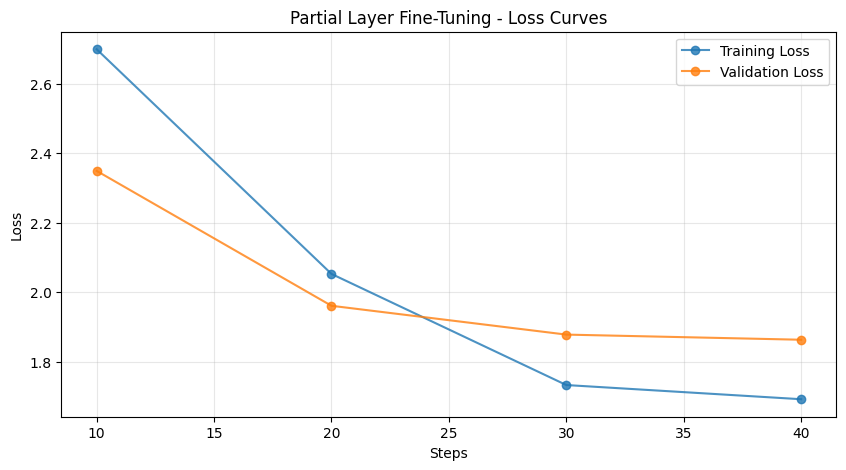

In [11]:
print("\n--- Training Documentation ---")
print(f"Total training time: {train_result.metrics['train_runtime']:.2f} seconds")
print(f"Final training loss: {train_result.metrics['train_loss']:.4f}")
print("Challenges: The main challenge was managing GPU memory. Even with bfloat16 and a small dataset, traditional fine-tuning is resource-intensive. Gradient accumulation was essential.")

def plot_training_history(trainer, title):
    """Plots training and validation loss curves."""
    if hasattr(trainer, 'state') and trainer.state.log_history:
        df = pd.DataFrame(trainer.state.log_history)
        train_logs = df[df['loss'].notna()]
        eval_logs = df[df['eval_loss'].notna()]

        plt.figure(figsize=(10, 5))
        if not train_logs.empty:
            plt.plot(train_logs['step'], train_logs['loss'], 'o-', label='Training Loss', alpha=0.8)
        if not eval_logs.empty:
            plt.plot(eval_logs['step'], eval_logs['eval_loss'], 'o-', label='Validation Loss', alpha=0.8)

        plt.title(f'{title} - Loss Curves')
        plt.xlabel('Steps')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

plot_training_history(trainer, "Partial Layer Fine-Tuning")

# 6. EVALUATION

In [12]:
def test_model_properly(model, tokenizer, test_prompts):
    """Test model with properly formatted prompts"""
    results = []
    print("\n" + "=" * 60)
    print("MODEL EVALUATION")
    print("=" * 60)
    for i, test_case in enumerate(test_prompts, 1):
        print(f"\n--- Test Case {i} ---")
        user_text = test_case['user']
        print(f"Input: {user_text[:150]}...")

        combined_prompt = f"{test_case['system']}\n{user_text}"
        messages = [{"role": "user", "content": combined_prompt}]

        formatted_prompt = tokenizer.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True
        )
        inputs = tokenizer(
            formatted_prompt, return_tensors="pt", truncation=True, max_length=512
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=100)

        full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)
        response_only = full_response.split("<start_of_turn>model\n")[-1]

        print(f"Response: {response_only[:200]}...")
        results.append(response_only)
    return results

def create_test_prompts_from_conversations(conversations, num_samples=3):
    """Create test prompts from original conversations"""
    test_prompts = []
    # Use the end of the list to avoid data seen during training the subset
    for conv in conversations[-num_samples:]:
        test_prompts.append({
            'system': conv[0]['content'],
            'user': conv[1]['content'],
        })
    return test_prompts

test_prompts = create_test_prompts_from_conversations(all_conversations, num_samples=3)

# Evaluate the fine-tuned model
final_results = test_model_properly(model, tokenizer, test_prompts)

# Save the final model
trainer.save_model("./final_partial_finetuned_model")
tokenizer.save_pretrained("./final_partial_finetuned_model")
print("\n✓ Final model saved to './final_partial_finetuned_model'")


MODEL EVALUATION

--- Test Case 1 ---
Input: مقاله‌ای بنویسید که به سوال زیر پاسخ دهد: چند کشور در تاریخ ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتیک برقرار کردند؟...
Response: user
شما یک دستیار هوش مصنوعی هستید. به شما یک وظیفه داده خواهد شد. شما باید یک پاسخ دقیق و طولانی تولید کنید.
مقاله‌ای بنویسید که به سوال زیر پاسخ دهد: چند کشور در تاریخ ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتی...

--- Test Case 2 ---
Input: شما با این سوال مواجه هستید: "چه چیزی نقطه ذوب یک مایع را کاهش می‌دهد؟" و گزینه‌های زیر در دسترس است:  - انرژی حرارتی  - کم آبی  - لایه‌های چربی  - فر...
Response: user
شما یک دستیار هوش مصنوعی هستید. پاسخ دقیقی ارائه دهید تا کاربر نیازی به جستجوی اطلاعات در خارج نداشته باشد.
شما با این سوال مواجه هستید: "چه چیزی نقطه ذوب یک مایع را کاهش می‌دهد؟" و گزینه‌های زیر...

--- Test Case 3 ---
Input: لطفاً آخرین نظر مشاور عمومی کوکوت را که در تاریخ 29 مارس 2007 در مورد پرونده C‑287/05، هندریکس صادر شده است، ترجمه کنید (مجموعه ECLI، صفحه I‑6909، بند...
Response: user
شما یک دستیار هوش مصنوعی هستید. کاربر ی